# Reproducing the README tables

Every table in `README.md` (sections 2–4) is recomputed here from `data/frequency.parquet`,
using the same helpers as `src/mip`. Nothing is written to disk: the GLMs are refit in memory
(a few seconds each) and figures are only displayed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import mean_poisson_deviance

from mip.config import Config
from mip.DataUnderstand.group_analysis import grouping, take_logrithm
from mip.models.baseline import baseline_deviance
from mip.models.poissonGLM import one_hot_encode, offset_test, measure_noise

config = Config()
df_fre = pd.read_parquet(config.DATA_DIR / "frequency.parquet")

## 2. Data

In [2]:
claim_dist = df_fre["ClaimNb"].value_counts(normalize=True).sort_index() * 100
overall_freq = df_fre["ClaimNb"].sum() / df_fre["Exposure"].sum()

print(f"Policies: {len(df_fre):,}")
print(f"Overall observed frequency: {overall_freq:.3f} claims per policy-year")
print(f'{claim_dist[0]:.2f}% of policies have no claims.')
print(f"{(df_fre['Exposure'] > 1).mean() * 100:.2f}% of policies have Exposure > 1 (not capped).")

Policies: 678,013
Overall observed frequency: 0.101 claims per policy-year
94.98% of policies have no claims.
0.18% of policies have Exposure > 1 (not capped).


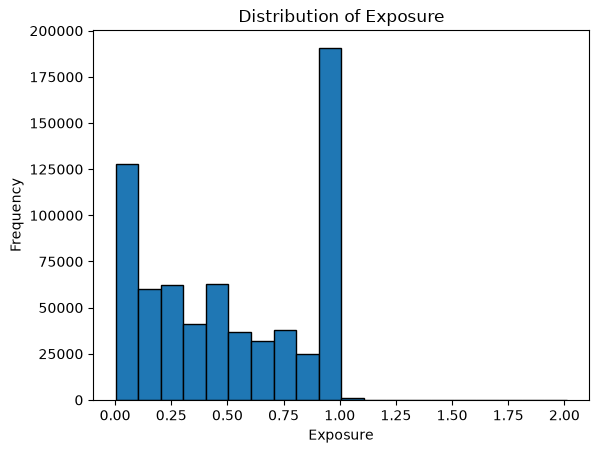

In [3]:
plt.hist(df_fre["Exposure"], bins=20, edgecolor='black')
plt.title("Distribution of Exposure")
plt.xlabel("Exposure")
plt.ylabel("Frequency")
plt.show()

## 3.2 Features

Same binning as `src/mip/models/poissonGLM.py`. The reference level (first category) is dropped
by `one_hot_encode`. `BonusMalus2Group` (≤ 100 / > 100) is only used for the comparison in 4.3,
`Area` only for 4.4.

In [4]:
df = df_fre.copy()
df["logDensity"] = take_logrithm(df, column_name="Density")
for col in ["VehPower", "VehAge", "logDensity"]:
    df[f"{col}Group"] = grouping(df, group_column=col)
df["DrivAgeGroup"] = grouping(df, group_column="DrivAge",
                              bins=[17, 25, 35, 45, 55, 65, df["DrivAge"].max()])
df["BonusMalusGroup"] = grouping(df, "BonusMalus", bins=[49, 50, 90, 99, 100, 230],
                                 labels=["50", "51-90", "91-99", "100", "101+"])
df["BonusMalus2Group"] = grouping(df, "BonusMalus", bins=[49, 100, 230],
                                  labels=["<=100", "101+"])

categorical_cols = [
    "DrivAgeGroup",
    "BonusMalusGroup",
    "VehPowerGroup",
    "VehAgeGroup",
    "logDensityGroup",
    "VehGas",
    "VehBrand",
    "Region",
]


def levels(s: pd.Series) -> list:
    return list(s.cat.categories) if isinstance(s.dtype, pd.CategoricalDtype) else sorted(s.unique())


pd.DataFrame(
    {
        "Reference": [levels(df[c])[0] for c in categorical_cols],
        "Levels": [", ".join(map(str, levels(df[c]))) for c in categorical_cols],
    },
    index=pd.Index(categorical_cols, name="Feature"),
)

,Reference,Levels
Feature,,
DrivAgeGroup,"(17, 25]","(17, 25], (25, 35], (35, 45], (45, 55], (55, 6..."
BonusMalusGroup,50,"50, 51-90, 91-99, 100, 101+"
VehPowerGroup,"(3.999, 5.0]","(3.999, 5.0], (5.0, 6.0], (6.0, 7.0], (7.0, 8...."
VehAgeGroup,"(-0.001, 2.0]","(-0.001, 2.0], (2.0, 4.0], (4.0, 8.0], (8.0, 1..."
logDensityGroup,"(0.692, 4.22]","(0.692, 4.22], (4.22, 5.371], (5.371, 6.575], ..."
VehGas,'Diesel',"'Diesel', 'Regular'"
VehBrand,B1,"B1, B10, B11, B12, B13, B14, B2, B3, B4, B5, B6"
Region,R11,"R11, R21, R22, R23, R24, R25, R26, R31, R41, R..."


In [5]:
# The extra dummies do not change the split: it only depends on the row count and the seed.
train, test = one_hot_encode(df, categorical_cols + ["BonusMalus2Group", "Area"])
print(f"Train / test: {len(train):,} / {len(test):,} policies")


def fit_glm(categorical_cols: list):
    # Same model as mip.models.poissonGLM.poisson_glm, but without saving it.
    cols = [
        col for col in train.columns
        if col.startswith(tuple(name + "_" for name in categorical_cols))
    ]
    model = sm.GLM(
        train["ClaimNb"],
        sm.add_constant(train[cols]),
        family=sm.families.Poisson(),
        offset=np.log(train["Exposure"])
    )
    return model.fit()


results = fit_glm(categorical_cols)

saved = sm.load(config.SAVED_MODELS_DIR / 'poissonGLM' / "v0.0.1.pkl")
print("Same coefficients as saved model v0.0.1:",
      np.allclose(results.params, saved.params.reindex(results.params.index)))

Train / test: 542,410 / 135,603 policies
Same coefficients as saved model v0.0.1: True


## 4.1 Model performance

In [6]:
mu_test = offset_test(results, train, test)

baseline_dev, baseline_freq = baseline_deviance(train, test)
glm_dev = mean_poisson_deviance(test["ClaimNb"], mu_test)
noise = measure_noise(mu_test, n_sim=100, seed=0)

reducible_gap = baseline_dev - noise.mean()
print(f"Improvement over baseline: {1 - glm_dev / baseline_dev:.1%}")
print(f"Reducible gap (baseline - noise floor): {reducible_gap:.3f}")
print(f"Share of the reducible gap closed by the GLM: {(baseline_dev - glm_dev) / reducible_gap:.0%}")

pd.DataFrame(
    {"Mean Poisson deviance (test)": [
        f"{baseline_dev:.4f}",
        f"{glm_dev:.4f}",
        f"{noise.mean():.4f} ± {noise.std():.4f}",
    ]},
    index=pd.Index([
        "Baseline (constant frequency)",
        "Poisson GLM",
        "Noise floor (simulated, if GLM were the true model)",
    ], name="Model"),
)

offset test for train set:  28861.000000000135 28861
offset test for test set:  7202.018584959938 7241
Improvement over baseline: 3.2%
Reducible gap (baseline - noise floor): 0.048
Share of the reducible gap closed by the GLM: 22%


,Mean Poisson deviance (test)
Model,
Baseline (constant frequency),0.3314
Poisson GLM,0.3209
"Noise floor (simulated, if GLM were the true model)",0.2834 ± 0.0024


## 4.2 BonusMalus relativities

In [7]:
bm_relativity = np.exp(results.params.filter(like="BonusMalusGroup_"))
bm_relativity.index = bm_relativity.index.str.removeprefix("BonusMalusGroup_")
bm_relativity = pd.concat([pd.Series({"50": 1.0}), bm_relativity])

bm_relativity.rename_axis("BonusMalus").to_frame("Relativity vs. 50").round(2)

,Relativity vs. 50
BonusMalus,
50,1.00
51-90,1.66
91-99,2.48
100,3.85
101+,5.31


## 4.3 Confounding: young drivers vs. new drivers

Driver-age coefficients (log scale, vs. 18–25) from the same model, once with BonusMalus in
2 bins (≤ 100 / > 100) and once in the 5 bins above.

In [8]:
results_bm2 = fit_glm([
    "BonusMalus2Group" if c == "BonusMalusGroup" else c for c in categorical_cols
])

age_labels = {
    "(25, 35]": "26–35",
    "(35, 45]": "36–45",
    "(45, 55]": "46–55",
    "(55, 65]": "56–65",
    "(65, 100]": "66+",
}
age_coefs = pd.DataFrame({
    "BonusMalus in 2 bins": results_bm2.params.filter(like="DrivAgeGroup_"),
    "BonusMalus in 5 bins (100 separated)": results.params.filter(like="DrivAgeGroup_"),
})
age_coefs.index = age_coefs.index.str.removeprefix("DrivAgeGroup_").map(age_labels)

print(f"18–25 vs. 26–35 (5 bins): "
      f"{np.exp(-results.params['DrivAgeGroup_(25, 35]']):.2f}x")
age_coefs.rename_axis("Age").map("{:+.2f}".format)

18–25 vs. 26–35 (5 bins): 1.35x


,BonusMalus in 2 bins,BonusMalus in 5 bins (100 separated)
Age,,
26–35,-0.51,-0.30
36–45,-0.48,-0.03
46–55,-0.39,+0.15
56–65,-0.54,+0.02
66+,-0.47,+0.12


## 4.4 Other effects

In [9]:
relativities = np.exp(results.params)
print("Vehicle age relativities (vs. youngest bin):")
print(relativities.filter(like="VehAgeGroup_").round(2).to_string())
print(f"\nVehBrand B12: {relativities['VehBrand_B12']:.2f}x")
print(f"Pearson chi2 / d.f.: {results.pearson_chi2 / results.df_resid:.2f}")

Vehicle age relativities (vs. youngest bin):
VehAgeGroup_(2.0, 4.0]       0.70
VehAgeGroup_(4.0, 8.0]       0.76
VehAgeGroup_(8.0, 12.0]      0.72
VehAgeGroup_(12.0, 100.0]    0.55

VehBrand B12: 1.22x
Pearson chi2 / d.f.: 2.60


In [10]:
# Density vs. Area: top logDensity bin with and without Area in the model.
results_area = fit_glm(categorical_cols + ["Area"])

top_density = results.params.filter(like="logDensityGroup_").index[-1]
print(f"Top density bin: {top_density}")
print(f"Training deviance change when dropping Area: "
      f"{results.deviance - results_area.deviance:.1f} "
      f"for {len(results_area.params) - len(results.params)} fewer parameters")

pd.DataFrame(
    {
        "coef": [r.params[top_density] for r in (results_area, results)],
        "s.e.": [r.bse[top_density] for r in (results_area, results)],
        "p-value": [r.pvalues[top_density] for r in (results_area, results)],
    },
    index=["with Area", "Area dropped"],
).round(3)

Top density bin: logDensityGroup_(7.907, 10.204]
Training deviance change when dropping Area: 4.8 for 5 fewer parameters


,coef,s.e.,p-value
with Area,0.110,0.063,0.078
Area dropped,0.218,0.022,0.000


## 4.5 Noise floor

In [11]:
print(f"Irreducible share of the GLM's test deviance: {noise.mean() / glm_dev:.0%}")
print(f"z = (actual - simulated mean) / simulated s.d. = {(glm_dev - noise.mean()) / noise.std():.1f}")

pd.DataFrame(
    {"Mean Poisson deviance": [f"{noise.mean():.4f} ± {noise.std():.4f}", f"{glm_dev:.4f}"]},
    index=["Simulated (model assumed true)", "Actual test set"],
)

Irreducible share of the GLM's test deviance: 88%
z = (actual - simulated mean) / simulated s.d. = 15.6


,Mean Poisson deviance
Simulated (model assumed true),0.2834 ± 0.0024
Actual test set,0.3209


## 4.6 Calibration by risk decile

Same computation as `src/mip/evaluations/calibration_plot.py`: test policies sorted by predicted
frequency and split into 10 groups of equal exposure.

In [12]:
pred = test[["ClaimNb", "Exposure"]].assign(mu=mu_test)
pred["predicted_frequency"] = pred["mu"] / pred["Exposure"]
pred = pred.sort_values("predicted_frequency")
cum_exp = pred["Exposure"].cumsum() / pred["Exposure"].sum()     # 0 → 1
pred["decile"] = np.minimum((cum_exp * 10).astype(int), 9)         # 0 ~ 9

cal = pred.groupby("decile").agg(
    exposure=("Exposure", "sum"),
    pred_claims=("mu", "sum"),
    obs_claims=("ClaimNb", "sum"),
)
cal["pred_freq"] = cal["pred_claims"] / cal["exposure"]
cal["obs_freq"] = cal["obs_claims"] / cal["exposure"]
cal["obs_se"] = np.sqrt(cal["obs_claims"]) / cal["exposure"]
cal["z"] = (cal["pred_freq"] - cal["obs_freq"]) / cal["obs_se"]
cal.round(3)

,exposure,pred_claims,obs_claims,pred_freq,obs_freq,obs_se,z
decile,,,,,,,
0,7161.904,355.394,337,0.050,0.047,0.003,1.002
1,7162.949,440.287,412,0.061,0.058,0.003,1.394
2,7162.355,498.153,523,0.070,0.073,0.003,-1.086
3,7162.203,548.740,531,0.077,0.074,0.003,0.770
4,7162.555,596.730,616,0.083,0.086,0.003,-0.776
5,7162.546,652.696,654,0.091,0.091,0.004,-0.051
6,7162.133,727.339,746,0.102,0.104,0.004,-0.683
7,7162.383,827.385,857,0.116,0.120,0.004,-1.012
8,7162.937,972.751,1061,0.136,0.148,0.005,-2.709


In [13]:
portfolio_freq = pred["ClaimNb"].sum() / pred["Exposure"].sum()
print(f"Riskiest / safest decile (observed): {cal['obs_freq'].iloc[-1] / cal['obs_freq'].iloc[0]:.1f}x")
print(f"Deciles with |pred - obs| < 1.5 s.e.: {(cal['z'].abs() < 1.5).sum()} of {len(cal)}")
print(f"Total predicted vs. observed claims: {pred['mu'].sum() / pred['ClaimNb'].sum() - 1:+.2%}")
print(f"Policies predicted below the portfolio average: "
      f"{(pred['predicted_frequency'] < portfolio_freq).mean():.0%}")

readme_cal = cal.loc[[0, 5, 8, 9], ["pred_freq", "obs_freq"]].round(3)
readme_cal.index = ["0 (safest)", "5", "8", "9 (riskiest)"]
readme_cal.rename_axis("Decile").rename(
    columns={"pred_freq": "Predicted freq.", "obs_freq": "Observed freq."}
)

Riskiest / safest decile (observed): 4.5x
Deciles with |pred - obs| < 1.5 s.e.: 8 of 10
Total predicted vs. observed claims: -0.54%
Policies predicted below the portfolio average: 58%


,Predicted freq.,Observed freq.
Decile,,
0 (safest),0.050,0.047
5,0.091,0.091
8,0.136,0.148
9 (riskiest),0.221,0.210


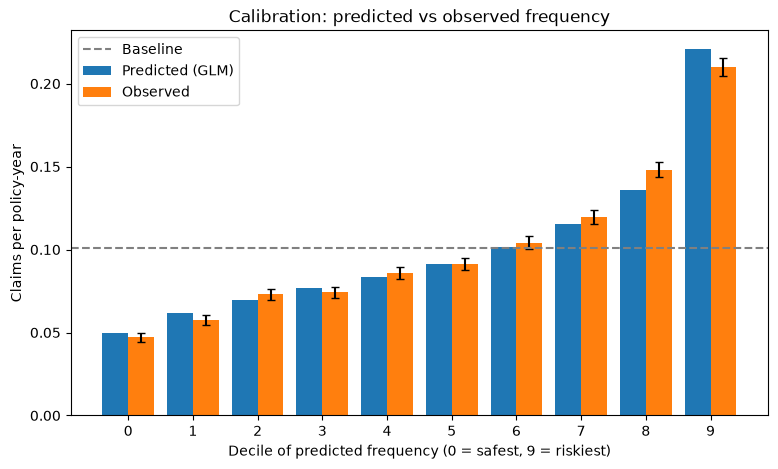

In [14]:
x = cal.index
width = 0.4

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, cal["pred_freq"], width, label="Predicted (GLM)")
plt.bar(x + width/2, cal["obs_freq"],  width, yerr=cal["obs_se"], capsize=3, label="Observed")
plt.axhline(portfolio_freq, color="gray", linestyle="--", label="Baseline")

plt.xlabel("Decile of predicted frequency (0 = safest, 9 = riskiest)")
plt.ylabel("Claims per policy-year")
plt.title("Calibration: predicted vs observed frequency")
plt.xticks(x)
plt.legend()
plt.show()